# Analysis of the Credit Dataset

In [140]:
# libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import missingno as msno

## <font color="orange"> Load and inspect the data </font>

In [141]:
# load
path = "../data/raw-data/Credit_Risk_Data.csv"
df = pd.read_csv(path)

In [142]:
# data schemas
print(df.info())
df.head()

<class 'pandas.DataFrame'>
RangeIndex: 32581 entries, 0 to 32580
Data columns (total 29 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   client_ID                   32581 non-null  str    
 1   person_age                  32581 non-null  int64  
 2   person_income               32581 non-null  int64  
 3   person_home_ownership       32581 non-null  str    
 4   person_emp_length           31686 non-null  float64
 5   loan_intent                 32581 non-null  str    
 6   loan_grade                  32581 non-null  str    
 7   loan_amnt                   32581 non-null  int64  
 8   loan_int_rate               29465 non-null  float64
 9   loan_status                 32581 non-null  int64  
 10  loan_percent_income         32581 non-null  float64
 11  cb_person_default_on_file   32581 non-null  str    
 12  cb_person_cred_hist_length  32581 non-null  int64  
 13  gender                      32581 non-null

,client_ID,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,...,city_latitude,city_longitude,employment_type,loan_term_months,loan_to_income_ratio,other_debt,debt_to_income_ratio,open_accounts,credit_utilization_ratio,past_delinquencies
0,CUST_00001,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,...,43.6532,-79.3832,Self-employed,36,0.593220,8402.453850,0.735635,14,0.495557,0
1,CUST_00002,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,...,43.6532,-79.3832,Full-time,36,0.104167,1607.802794,0.271646,10,0.585436,3
2,CUST_00003,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,...,51.6214,-3.9436,Full-time,36,0.572917,2760.505633,0.860469,14,0.750732,0
3,CUST_00004,23,65500,RENT,4.0,MEDICAL,C,35000,15.23,1,...,49.2827,-123.1207,Part-time,12,0.534351,7155.286150,0.643592,15,0.379333,0
4,CUST_00005,24,54400,RENT,8.0,MEDICAL,C,35000,14.27,1,...,42.8864,-78.8784,Part-time,36,0.643382,15626.153440,0.930628,4,0.228103,0


In [143]:
# basic statistical description
## object
print(df.drop(columns=['client_ID']).describe(include=["object", str]).T)
print("\n")
## numerics
df.drop(columns=['client_ID']).describe(include="number").round(3).T


                           count unique          top   freq
person_home_ownership      32581      4         RENT  16446
loan_intent                32581      6    EDUCATION   6453
loan_grade                 32581      7            A  10777
cb_person_default_on_file  32581      2            N  26836
gender                     32581      2         Male  16371
marital_status             32581      4       Single  16368
education_level            32581      4  High School  13185
country                    32581      3           UK  10944
state                      32581      9           BC   3679
city                       32581     18     Victoria   1852
employment_type            32581      4    Full-time  19473




,count,mean,std,min,25%,50%,75%,max
person_age,32581.0,27.735,6.348,20.000,23.000,26.000,30.000,144.000
person_income,32581.0,66074.848,61983.119,4000.000,38500.000,55000.000,79200.000,6000000.000
person_emp_length,31686.0,4.790,4.143,0.000,2.000,4.000,7.000,123.000
loan_amnt,32581.0,9589.371,6322.087,500.000,5000.000,8000.000,12200.000,35000.000
loan_int_rate,29465.0,11.012,3.240,5.420,7.900,10.990,13.470,23.220
loan_status,32581.0,0.218,0.413,0.000,0.000,0.000,0.000,1.000
loan_percent_income,32581.0,0.170,0.107,0.000,0.090,0.150,0.230,0.830
cb_person_cred_hist_length,32581.0,5.804,4.055,2.000,3.000,4.000,8.000,30.000
city_latitude,32581.0,45.408,7.645,29.760,40.713,46.814,51.507,55.953
city_longitude,32581.0,-63.805,46.616,-123.366,-96.797,-75.697,-3.944,-0.128


**Comment:** There are abnormalities in the ``person_age`` and ``person_emp_length``, where the corresponding ranges cross 100 years (up to 144 years for age, and 123 years for employment length). These need to be carefully treated. 

In [144]:
# column name normalization: add units to column names
cols_name = df.columns.to_list()
for i, col in enumerate(cols_name):
    if col == "person_age":
        cols_name[i] = "person_age_years"
    if col == "person_income":
        cols_name[i] = "person_income_usd"
    if col == "person_emp_length":
        cols_name[i] = "person_emp_length_years"
    if col == "loan_amnt":
        cols_name[i] = "loan_amount_usd"
    if col == "other_debt":
        cols_name[i] = "other_debt_usd"
    if col == "cb_person_cred_hist_length":
        cols_name[i] = "cb_person_cred_hist_length_years"
    
print(cols_name)
df.columns = cols_name


['client_ID', 'person_age_years', 'person_income_usd', 'person_home_ownership', 'person_emp_length_years', 'loan_intent', 'loan_grade', 'loan_amount_usd', 'loan_int_rate', 'loan_status', 'loan_percent_income', 'cb_person_default_on_file', 'cb_person_cred_hist_length_years', 'gender', 'marital_status', 'education_level', 'country', 'state', 'city', 'city_latitude', 'city_longitude', 'employment_type', 'loan_term_months', 'loan_to_income_ratio', 'other_debt_usd', 'debt_to_income_ratio', 'open_accounts', 'credit_utilization_ratio', 'past_delinquencies']


## <font color="orange"> Missing value analysis <font>

In [145]:
# count
null_stat = pd.DataFrame(df.isna().sum().sort_values(ascending=False)).reset_index()
null_stat.columns = ["feature", "null_count"]
null_stat["null_pct"] = null_stat["null_count"] / len(df) * 100
print(null_stat[null_stat["null_count"] > 0])

                   feature  null_count  null_pct
0            loan_int_rate        3116  9.563856
1  person_emp_length_years         895  2.747000


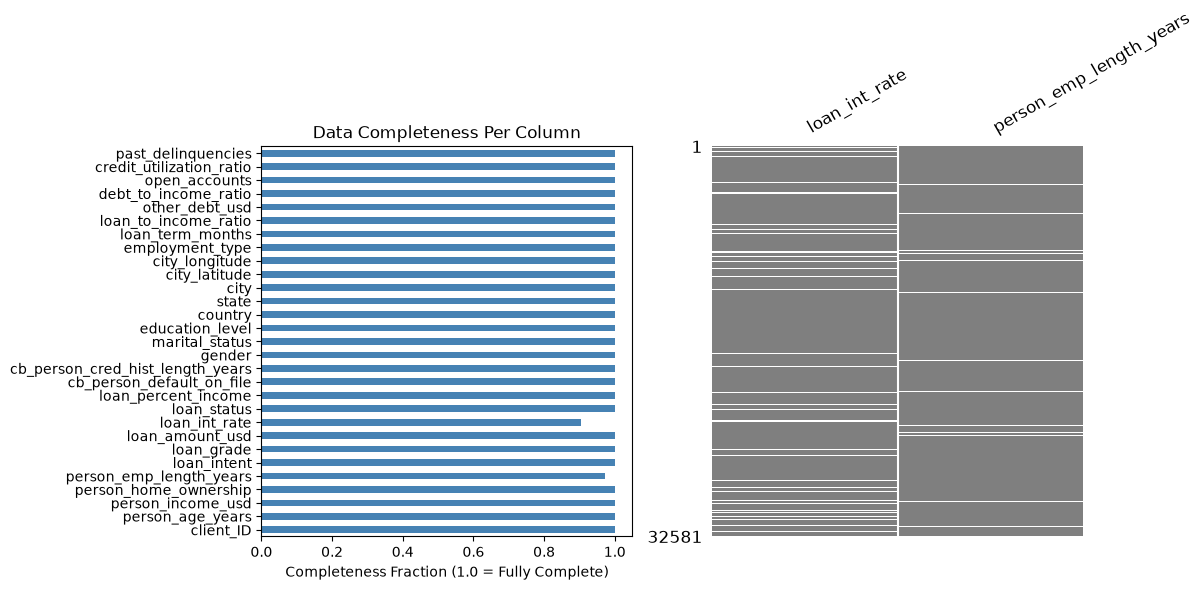

In [146]:
# distribution of missing values
null_cols = null_stat[null_stat["null_count"] > 0]["feature"]
completeness = df.notna().mean()
fig, ax = plt.subplots(1, 2, figsize=(12, 6))
completeness.plot(kind='barh', color='steelblue', ax=ax[0])
msno.matrix(df[null_cols], figsize=(12, 6), color=(0.5, 0.5, 0.5), sparkline=False, ax=ax[1])
ax[1].set_xticklabels(ax[1].get_xticklabels(), rotation=30, fontsize=12)
ax[1].set_yticklabels(ax[1].get_yticklabels(), fontsize=12)
ax[0].set_title('Data Completeness Per Column')
ax[0].set_xlabel('Completeness Fraction (1.0 = Fully Complete)')
plt.tight_layout()

Now, we are going to test if the nulls in loan_int_rate and person_emp_lenth_years are associated with other presented features (univariate test only).  

For the numerics columns, we use the Mann-Whitney U test (two-sided).
- H0: same distribution among null rows and non-null rows.
- H1: the distributions are different -> some association

For the cateogrial columns, we use the chi-square test of independency
- H0: missingness is independent of the considered feature (null rate is the same in every category)
- H1: missingness depends on the considered feature. Null rate differs across at least one category.

Significant level: $ \alpha = 0.05$

In [147]:
from scipy.stats import mannwhitneyu, chi2_contingency
from statsmodels.stats.multitest import multipletests

def missingness_univariate_analysis(
    df: pd.DataFrame, 
    target_col: str, 
    excluded_cols: list[str],
    alpha: float=0.05,
) -> pd.DataFrame:
    """
    Perform univariate tests for association with missingness in the target column.
    """
    missing = df[target_col].isna().astype(int)
    results = []

    for col in df.columns:
        if col == target_col or col in excluded_cols:
            continue
        s = df[col]

        if pd.api.types.is_bool_dtype(s) or not pd.api.types.is_numeric_dtype(s): 
            ## chi-square test for categorical variables
            ct = pd.crosstab(s, missing)
            if ct.shape[0] < 2 or ct.shape[1] < 2:
                continue
            chi2, p, _, _ = chi2_contingency(ct)
            n = ct.values.sum()
            effect = (chi2 / (n * (min(ct.shape) - 1))) ** 0.5   # Cramér's V
            results.append((col, "categorical", p, effect))
        else:
            ## Mann-Whitney U test for numeric variables
            g1 = s[missing == 0].dropna().astype(float)
            g2 = s[missing == 1].dropna().astype(float)
            if len(g1) == 0 or len(g2) == 0:
                continue
            u, p = mannwhitneyu(g1, g2)
            effect = 2 * u / (len(g1) * len(g2)) - 1             # rank-biserial
            results.append((col, "numeric", p, effect))

    out = pd.DataFrame(results, columns=["feature", "type", "p_value", "effect_size"])
    if out.empty:
        return out
    # Benjamini-Hochberg false discovery rate (fdr) correction for multiple testing  
    reject, p_adj, _, _ = multipletests(out["p_value"], alpha=alpha, method="fdr_bh")
    out["p_adj_bh"] = p_adj
    out["significant"] = reject
    return out.sort_values("p_adj_bh").reset_index(drop=True)

In [148]:
excluded_cols = ["client_ID", "loan_status", "city_longitude", "city_latitude"]

# loan_int_rate missingness analysis
loan_missing_results = missingness_univariate_analysis(df, "loan_int_rate", excluded_cols)

# person_emp_length_years missingness analysis
emp_missing_results = missingness_univariate_analysis(df, "person_emp_length_years", excluded_cols)

In [149]:
display(loan_missing_results)

,feature,type,p_value,effect_size,p_adj_bh,significant
0,open_accounts,numeric,0.004203,0.031064,0.100876,False
1,person_home_ownership,categorical,0.275700,0.010901,0.748579,False
2,loan_grade,categorical,0.106048,0.017930,0.748579,False
3,loan_percent_income,numeric,0.436671,-0.008455,0.748579,False
4,cb_person_cred_hist_length_years,numeric,0.280079,-0.011633,0.748579,False
5,marital_status,categorical,0.410210,0.009405,0.748579,False
6,cb_person_default_on_file,categorical,0.402301,0.004640,0.748579,False
7,loan_intent,categorical,0.140866,0.015953,0.748579,False
8,loan_to_income_ratio,numeric,0.425729,-0.008663,0.748579,False
9,past_delinquencies,numeric,0.353390,-0.008747,0.748579,False


In [150]:
display(emp_missing_results)

,feature,type,p_value,effect_size,p_adj_bh,significant
0,person_income_usd,numeric,1.589535e-98,0.412251,3.814883e-97,True
1,other_debt_usd,numeric,8.174964e-58,0.313658,9.809956e-57,True
2,loan_amount_usd,numeric,6.913054e-43,0.268448,5.530443e-42,True
3,person_home_ownership,categorical,2.998603e-37,0.072849,1.799162e-36,True
4,loan_int_rate,numeric,4.524031e-20,0.186829,2.171535e-19,True
5,loan_grade,categorical,1.191701e-13,0.047207,4.766804e-13,True
6,loan_percent_income,numeric,1.255866e-06,-0.094793,4.305828e-06,True
7,loan_to_income_ratio,numeric,1.931727e-06,-0.093159,5.795180e-06,True
8,debt_to_income_ratio,numeric,3.965025e-06,-0.090279,1.057340e-05,True
9,cb_person_default_on_file,categorical,2.382491e-04,0.020358,5.717978e-04,True


**Conclusion:** After Benjamini-Hochberg correction, 
- No variable was significantly associated with missingness in ``loan_int_rate``.
- Several variables are associate with missingness pattern in ``person_emp_length``

The first seems to be MCAR (missing completely at Random), while the later seem to be MAR (missing at random).
The rate of missingness are relatively small ( < 10%).

-> kNN imputation should be an appropriate choice.  
(Tree algorithms (RandomForest, XGBoost) have intrinsic treatment for missingness already)



## <font color="orange"> Duplication analysis <font>

In [151]:
# features-only
X = df.drop(columns=["clien_ID","loan_status"], errors="ignore")
X_extended = df.drop(columns=["clien_ID"], errors="ignore")

# check for duplicates in the data: full df and X
print("Full dataset:", df.duplicated().sum())
print("Features only:", X.duplicated().sum())
print("Extended features:", X_extended.duplicated().sum())

Full dataset: 0
Features only: 0
Extended features: 0


**Comment:** No duplicates detected.

## <font color="orange"> Target distribution </font>

On train set:
   loan_status  count  percentage
0            0  25473   78.183604
1            1   7108   21.816396


<Axes: xlabel='loan_status', ylabel='percent'>

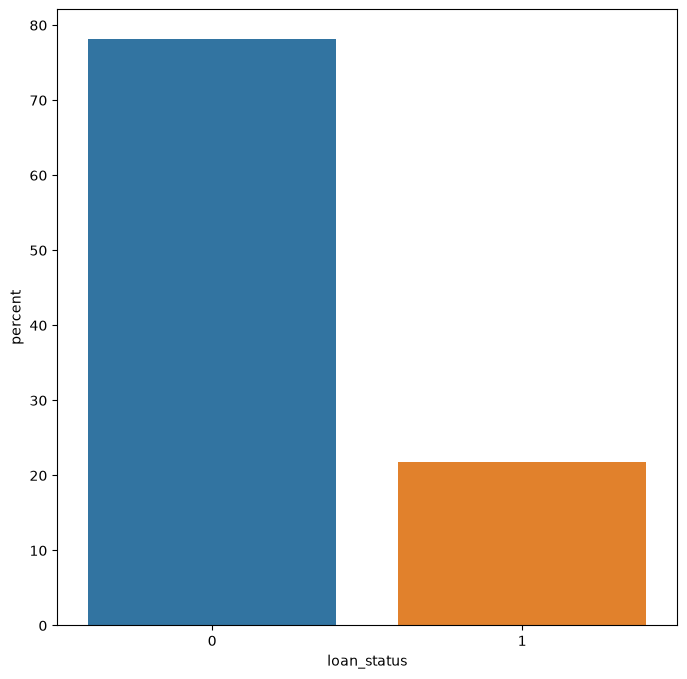

In [152]:
# on the train set, before and after dropping duplicates
target_col = "loan_status"
def target_distrib(df: pd.DataFrame, target_col: str, which: str):
    target = df[target_col].value_counts().to_frame().reset_index()
    target["percentage"] = 100*target["count"] / len(df)
    print(f"On {which}:")
    print(target)

target_distrib(df, target_col, "train set")

fig, ax = plt.subplots(figsize=(8,8))
sns.countplot(data=df, x=target_col, hue=target_col, stat="percent", legend=False, ax=ax)

**Comment:** 
- Class imbalance is mild:   
            default (1) : non-default (0) = 1 : 3.58 (78.18% : 21.82%)  

## <font color="orange">Target distribution by features <font>

In [153]:
# demographic and financial features
dem_features = [
    "person_home_ownership", 
    "person_emp_length_years", 
    "person_income_usd", 
    "person_age_years", 
    "marital_status", 
    "gender", 
    "country",
    "employment_type",
    "education_level", 
    "city", "state",
]
fin_features = [ft for ft in df.columns if ft not in dem_features + ["client_ID", "loan_status", "city_longitude", "city_latitude"]]

# numeric and categorical features
num_features = df.select_dtypes(include=["number"]).columns.to_list()
num_features = [ft for ft in num_features if ft not in ["client_ID", "loan_status", "city_longitude", "city_latitude"]]
cat_features = df.select_dtypes(include=[str, "bool"]).columns.to_list()
cat_features = [ft for ft in cat_features if ft not in ["client_ID", "loan_status"]]

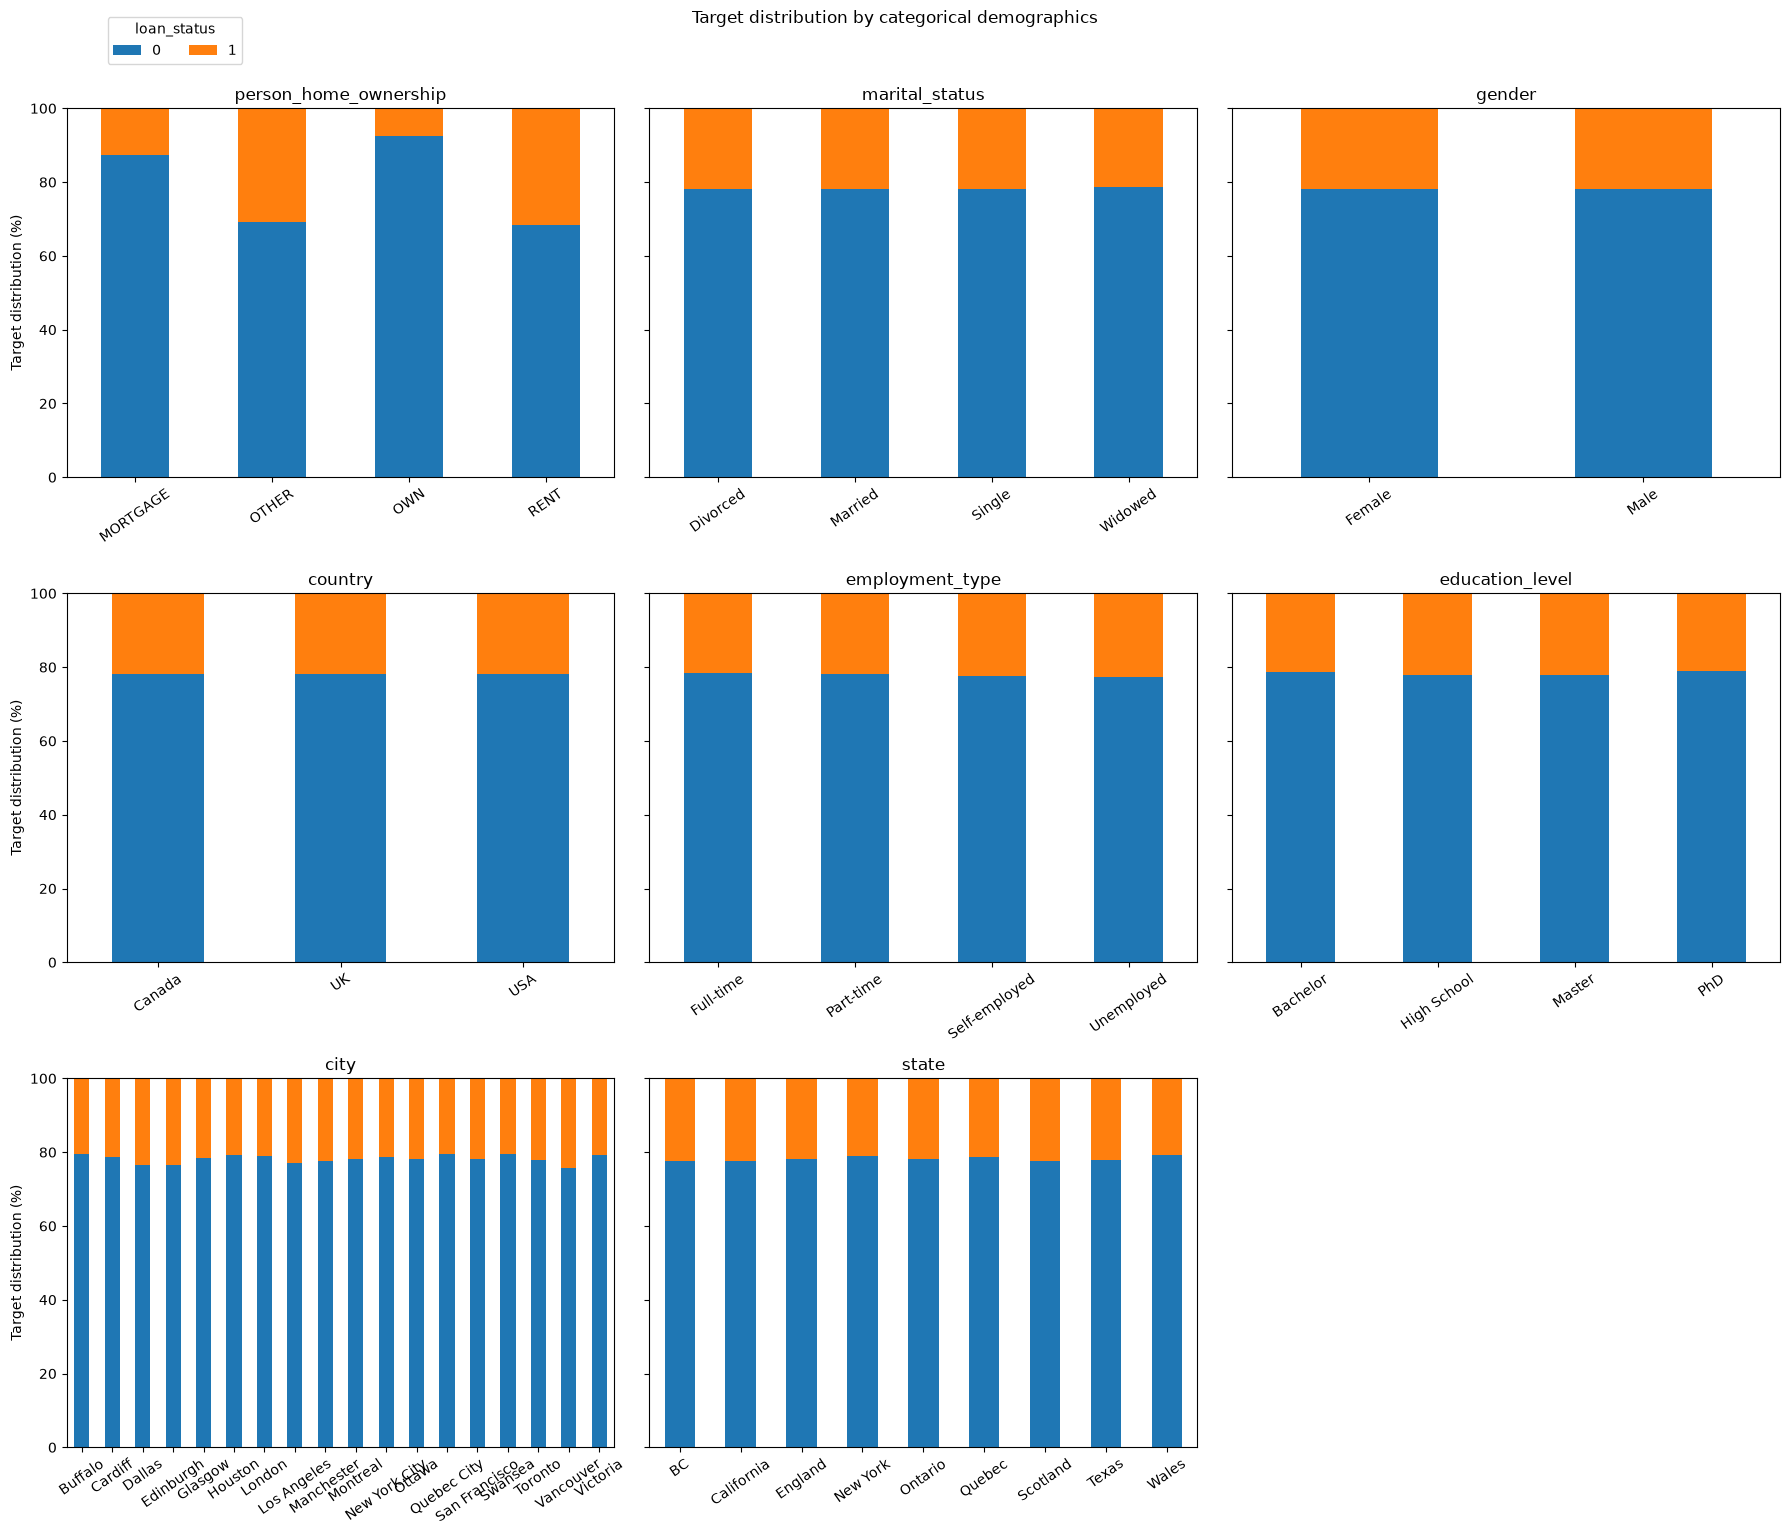

In [154]:
# target distribution for categorical demographic features
target_col = "loan_status"
cat_dem_features = [dem_ft for dem_ft in dem_features if dem_ft in cat_features]
ncols = 3
nrows = (len(cat_dem_features) + ncols - 1) // ncols
fig, axes = plt.subplots(nrows, ncols, figsize=(18, 5 * nrows), sharey=True)
axes = np.atleast_1d(axes).ravel()

for ax, col in zip(axes, cat_dem_features):
    proportions = pd.crosstab(
        df[col],
        df[target_col],
        normalize="index",
        dropna=False,
    ).mul(100)

    proportions.plot(kind="bar", stacked=True, ax=ax, legend=False)
    ax.set_title(col)
    ax.set_xlabel("")
    ax.set_ylabel("Target distribution (%)")
    ax.set_ylim(0, 100)
    ax.tick_params(axis="x", rotation=35)

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(
    handles, labels, 
    title=target_col, 
    loc="upper center", 
    bbox_to_anchor=(0.1, 1.02), 
    ncol=len(labels)
)
for ax in axes[len(cat_dem_features):]:
    ax.set_visible(False)

fig.suptitle("Target distribution by categorical demographics", y=1.02)
plt.tight_layout()
plt.show()

**Comments:** In categorical demographic features
- only home ownership has significant difference in distribution
- there are differences among cities and states, but they are very small. Keeping these would make the dataset sparse after encoding (introducing about 25 new cols) -> harmful rather than helpful


In [155]:
# keep only the categorical demographic features that are significant 
# in either the missingness analysis or the target distribution analysis 
kept_cat_dem_features = ["person_home_ownership"]

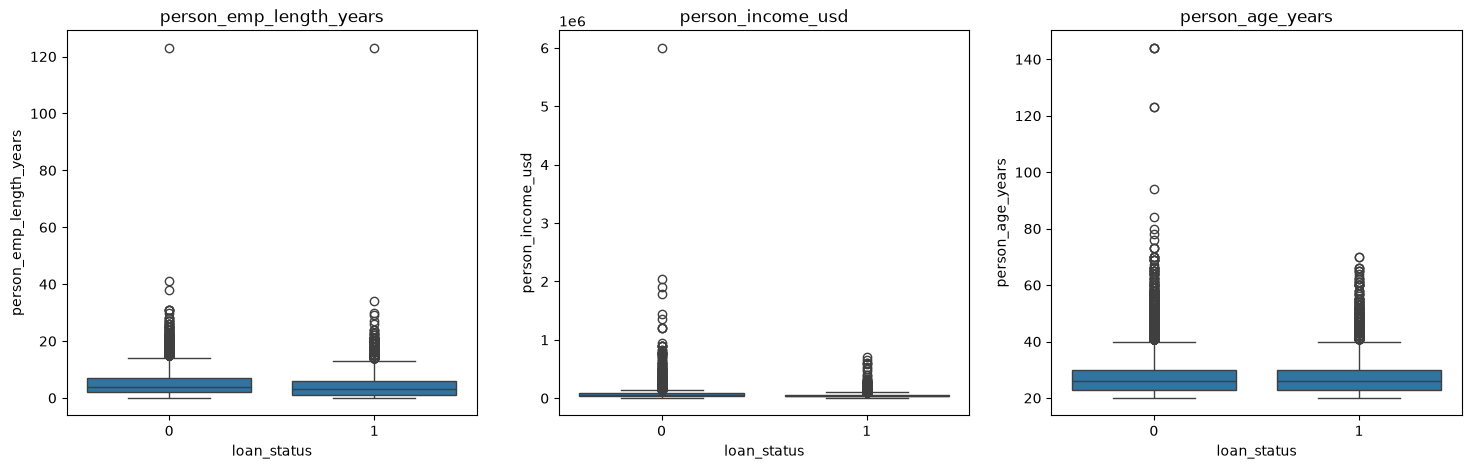

In [156]:
# target distribution for numerical demographic features
target_col = "loan_status"
num_dem_features = [dem_ft for dem_ft in dem_features if dem_ft in num_features]
ncols = 3
nrows = (len(num_dem_features) + ncols - 1) // ncols
fig, axes = plt.subplots(nrows, ncols, figsize=(18, 5 * nrows))
axes = np.atleast_1d(axes).ravel()
for ft, ax in zip(num_dem_features, axes):
    sns.boxplot(x=df[target_col], y=df[ft], ax=ax)
    ax.set_title(ft)
    #ax.set_xlabel("")
    #ax.set_ylabel("")
for ax in axes[len(num_dem_features):]:
    ax.set_visible(False)

In [157]:
# check for abnormality in person_emp_length_years and person_age_years
display(df[df["person_emp_length_years"] > 100])
display(df[df["person_age_years"] > 100])
display(df[df["person_emp_length_years"] >= df["person_age_years"]])


,client_ID,person_age_years,person_income_usd,person_home_ownership,person_emp_length_years,loan_intent,loan_grade,loan_amount_usd,loan_int_rate,loan_status,...,city_latitude,city_longitude,employment_type,loan_term_months,loan_to_income_ratio,other_debt_usd,debt_to_income_ratio,open_accounts,credit_utilization_ratio,past_delinquencies
0,CUST_00001,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,...,43.6532,-79.3832,Self-employed,36,0.593220,8402.45385,0.735635,14,0.495557,0
210,CUST_00211,21,192000,MORTGAGE,123.0,VENTURE,A,20000,6.54,0,...,51.6214,-3.9436,Full-time,36,0.104167,32653.09251,0.274235,6,0.482647,1


,client_ID,person_age_years,person_income_usd,person_home_ownership,person_emp_length_years,loan_intent,loan_grade,loan_amount_usd,loan_int_rate,loan_status,...,city_latitude,city_longitude,employment_type,loan_term_months,loan_to_income_ratio,other_debt_usd,debt_to_income_ratio,open_accounts,credit_utilization_ratio,past_delinquencies
81,CUST_00082,144,250000,RENT,4.0,VENTURE,C,4800,13.57,0,...,40.7128,-74.0060,Full-time,24,0.019200,3.865941e+04,0.173838,4,0.080767,0
183,CUST_00184,144,200000,MORTGAGE,4.0,EDUCATION,B,6000,11.86,0,...,48.4284,-123.3656,Full-time,36,0.030000,5.487376e+04,0.304369,1,0.053672,0
575,CUST_00576,123,80004,RENT,2.0,EDUCATION,B,20400,10.25,0,...,49.2827,-123.1207,Part-time,36,0.254987,2.133409e+04,0.521650,13,0.446131,0
747,CUST_00748,123,78000,RENT,7.0,VENTURE,B,20000,NaN,0,...,42.8864,-78.8784,Full-time,60,0.256410,1.094605e+04,0.396744,7,0.589120,1
32297,CUST_32298,144,6000000,MORTGAGE,12.0,PERSONAL,C,5000,12.73,0,...,29.7604,-95.3698,Self-employed,24,0.000833,1.187999e+06,0.198833,8,0.850584,0


,client_ID,person_age_years,person_income_usd,person_home_ownership,person_emp_length_years,loan_intent,loan_grade,loan_amount_usd,loan_int_rate,loan_status,...,city_latitude,city_longitude,employment_type,loan_term_months,loan_to_income_ratio,other_debt_usd,debt_to_income_ratio,open_accounts,credit_utilization_ratio,past_delinquencies
0,CUST_00001,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,...,43.6532,-79.3832,Self-employed,36,0.593220,8402.45385,0.735635,14,0.495557,0
210,CUST_00211,21,192000,MORTGAGE,123.0,VENTURE,A,20000,6.54,0,...,51.6214,-3.9436,Full-time,36,0.104167,32653.09251,0.274235,6,0.482647,1


**Comments:**
- There are rows with incredibly long employment (123 years), but the corresponding customers are just 21 and 22 years old. This could be some error in data input. 
- There are also customers with impressive age (123 and 144 yrs old), and the self-meployment/employment starts after 110 yrs old. These are unrealistic.

Luckily, only very few rows with these abnormal behaviors. It is safe to delete these.

   index   client_ID  person_age_years  person_income_usd  \
0      1  CUST_00002                21               9600   
1      2  CUST_00003                25               9600   
2      3  CUST_00004                23              65500   

  person_home_ownership  person_emp_length_years loan_intent loan_grade  \
0                   OWN                      5.0   EDUCATION          B   
1              MORTGAGE                      1.0     MEDICAL          C   
2                  RENT                      4.0     MEDICAL          C   

   loan_amount_usd  loan_int_rate  ...  city_latitude  city_longitude  \
0             1000          11.14  ...        43.6532        -79.3832   
1             5500          12.87  ...        51.6214         -3.9436   
2            35000          15.23  ...        49.2827       -123.1207   

  employment_type  loan_term_months loan_to_income_ratio other_debt_usd  \
0       Full-time                36             0.104167    1607.802794   
1       Ful

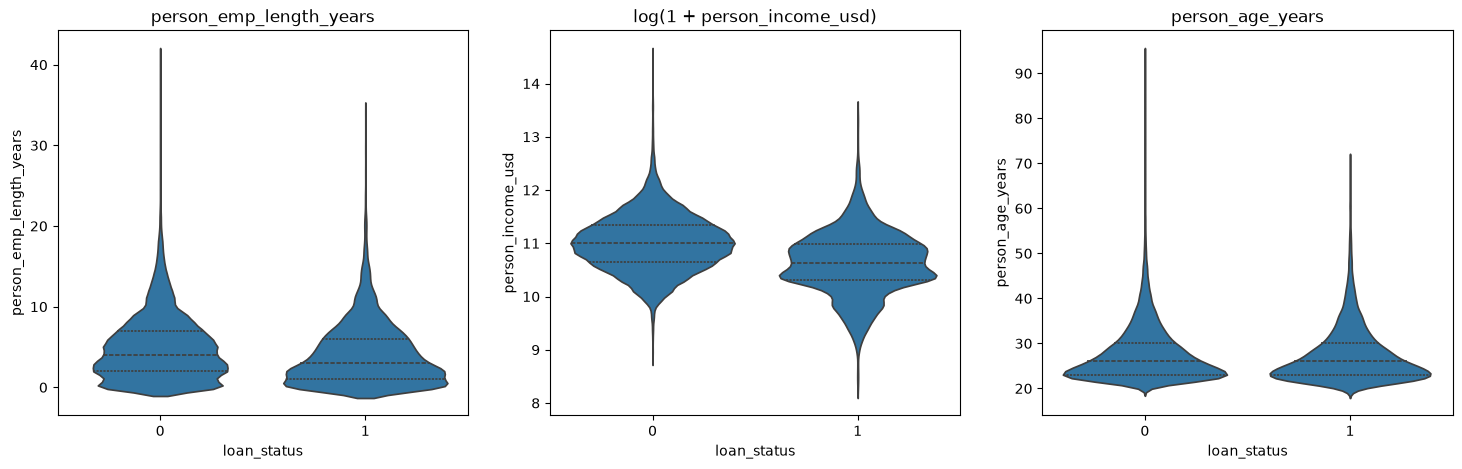

In [158]:
# keep only the rows where person_emp_length_years and person_age_years are less than or equal to 100
df = df[~(df["person_emp_length_years"] > 100)]
df = df[~(df["person_age_years"] > 100)]

# keep only rows where person_emp_length_years < person_age_years
df = df[~(df["person_emp_length_years"] >= df["person_age_years"])].reset_index()

print(df.head(3))

# plot again, but violin plots for better visualization of the distribution
ncols = 3
nrows = (len(num_dem_features) + ncols - 1) // ncols
fig, axes = plt.subplots(nrows, ncols, figsize=(18, 5 * nrows))
axes = np.atleast_1d(axes).ravel()
for ft, ax in zip(num_dem_features, axes):
    if ft == "person_income_usd":
        # plot log of person_income_usd
        sns.violinplot(x=df[target_col], y=np.log1p(df[ft]), inner="quartiles", ax=ax)
        ax.set_title(f"log(1 + {ft})")
    else:
        sns.violinplot(x=df[target_col], y=df[ft], inner="quartiles", ax=ax)
        ax.set_title(ft)
for ax in axes[len(num_dem_features):]:
    ax.set_visible(False)

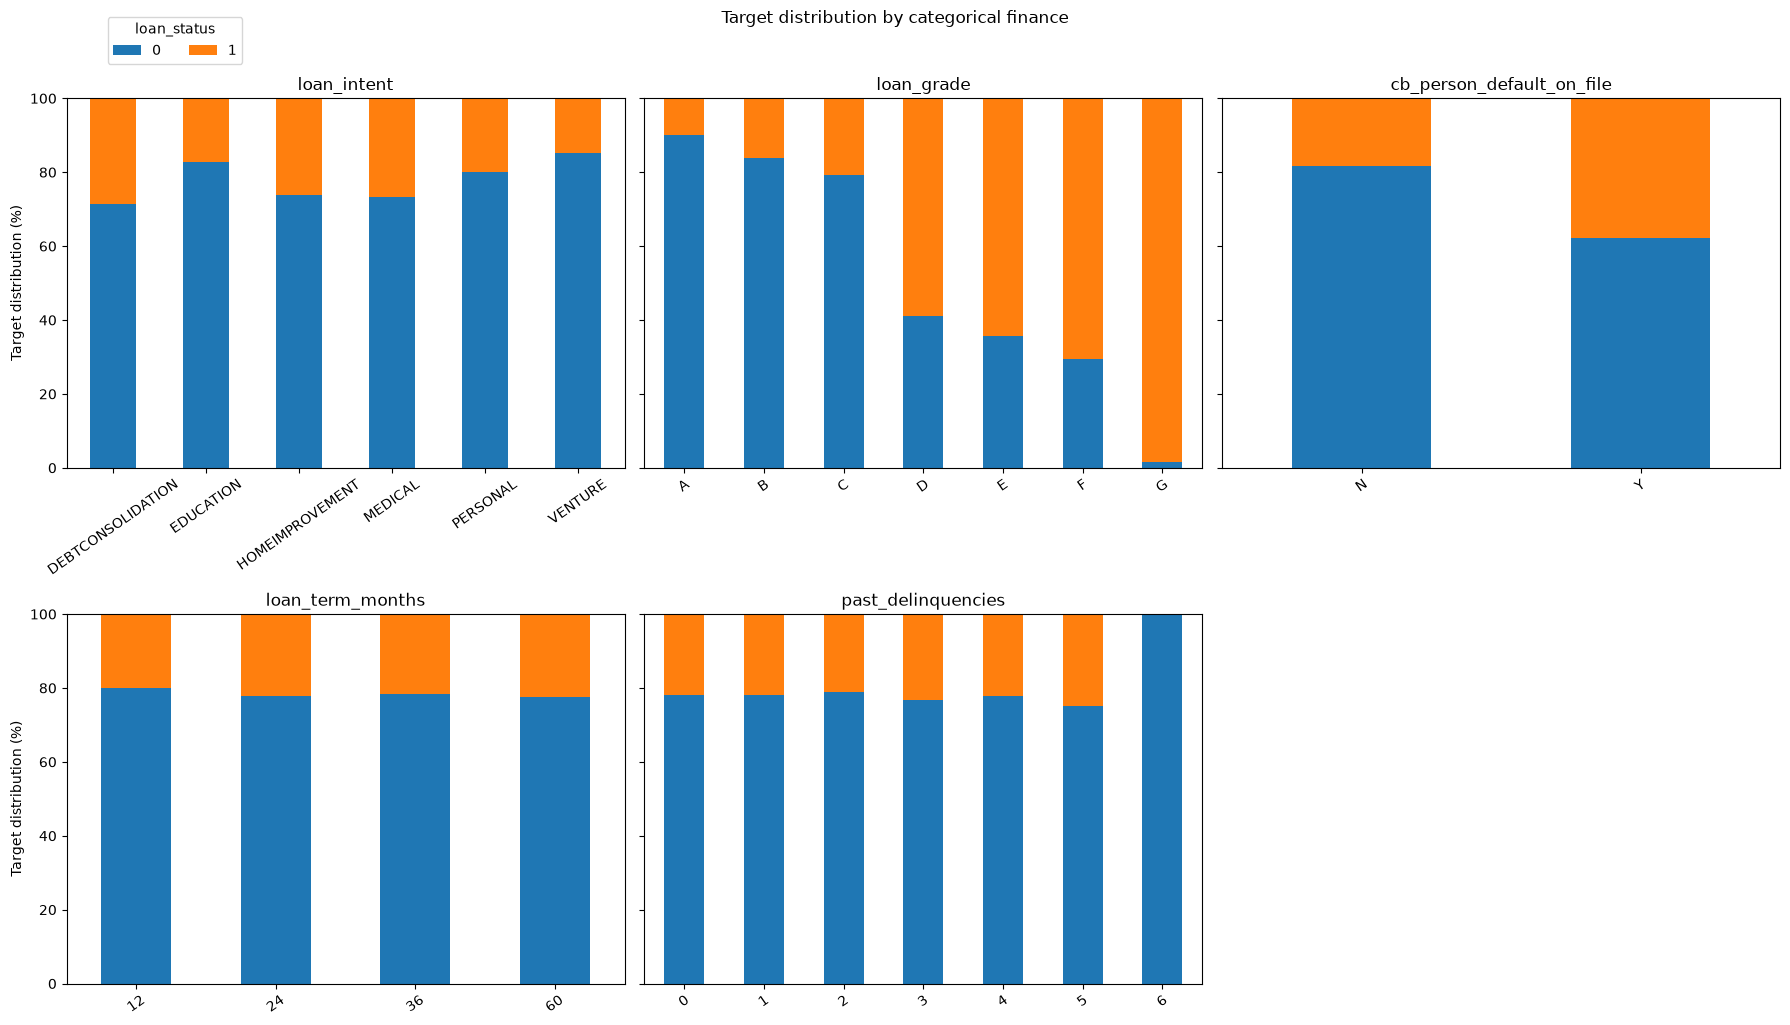

In [159]:
# target distribution for categorical financial features
target_col = "loan_status"
mixed = ["loan_term_months", "past_delinquencies"]
cat_fin_features = [ft for ft in fin_features if ft in cat_features + mixed]
ncols = 3
nrows = (len(cat_fin_features) + ncols - 1) // ncols
fig, axes = plt.subplots(nrows, ncols, figsize=(18, 5 * nrows), sharey=True)
axes = np.atleast_1d(axes).ravel()

for ax, col in zip(axes, cat_fin_features):
    proportions = pd.crosstab(
        df[col],
        df[target_col],
        normalize="index",
        dropna=False,
    ).mul(100)

    proportions.plot(kind="bar", stacked=True, ax=ax, legend=False)
    ax.set_title(col)
    ax.set_xlabel("")
    ax.set_ylabel("Target distribution (%)")
    ax.set_ylim(0, 100)
    ax.tick_params(axis="x", rotation=35)

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(
    handles, labels, 
    title=target_col, 
    loc="upper center", 
    bbox_to_anchor=(0.1, 1.02), 
    ncol=len(labels)
)
for ax in axes[len(cat_fin_features):]:
    ax.set_visible(False)

fig.suptitle("Target distribution by categorical finance", y=1.02)
plt.tight_layout()
plt.show()

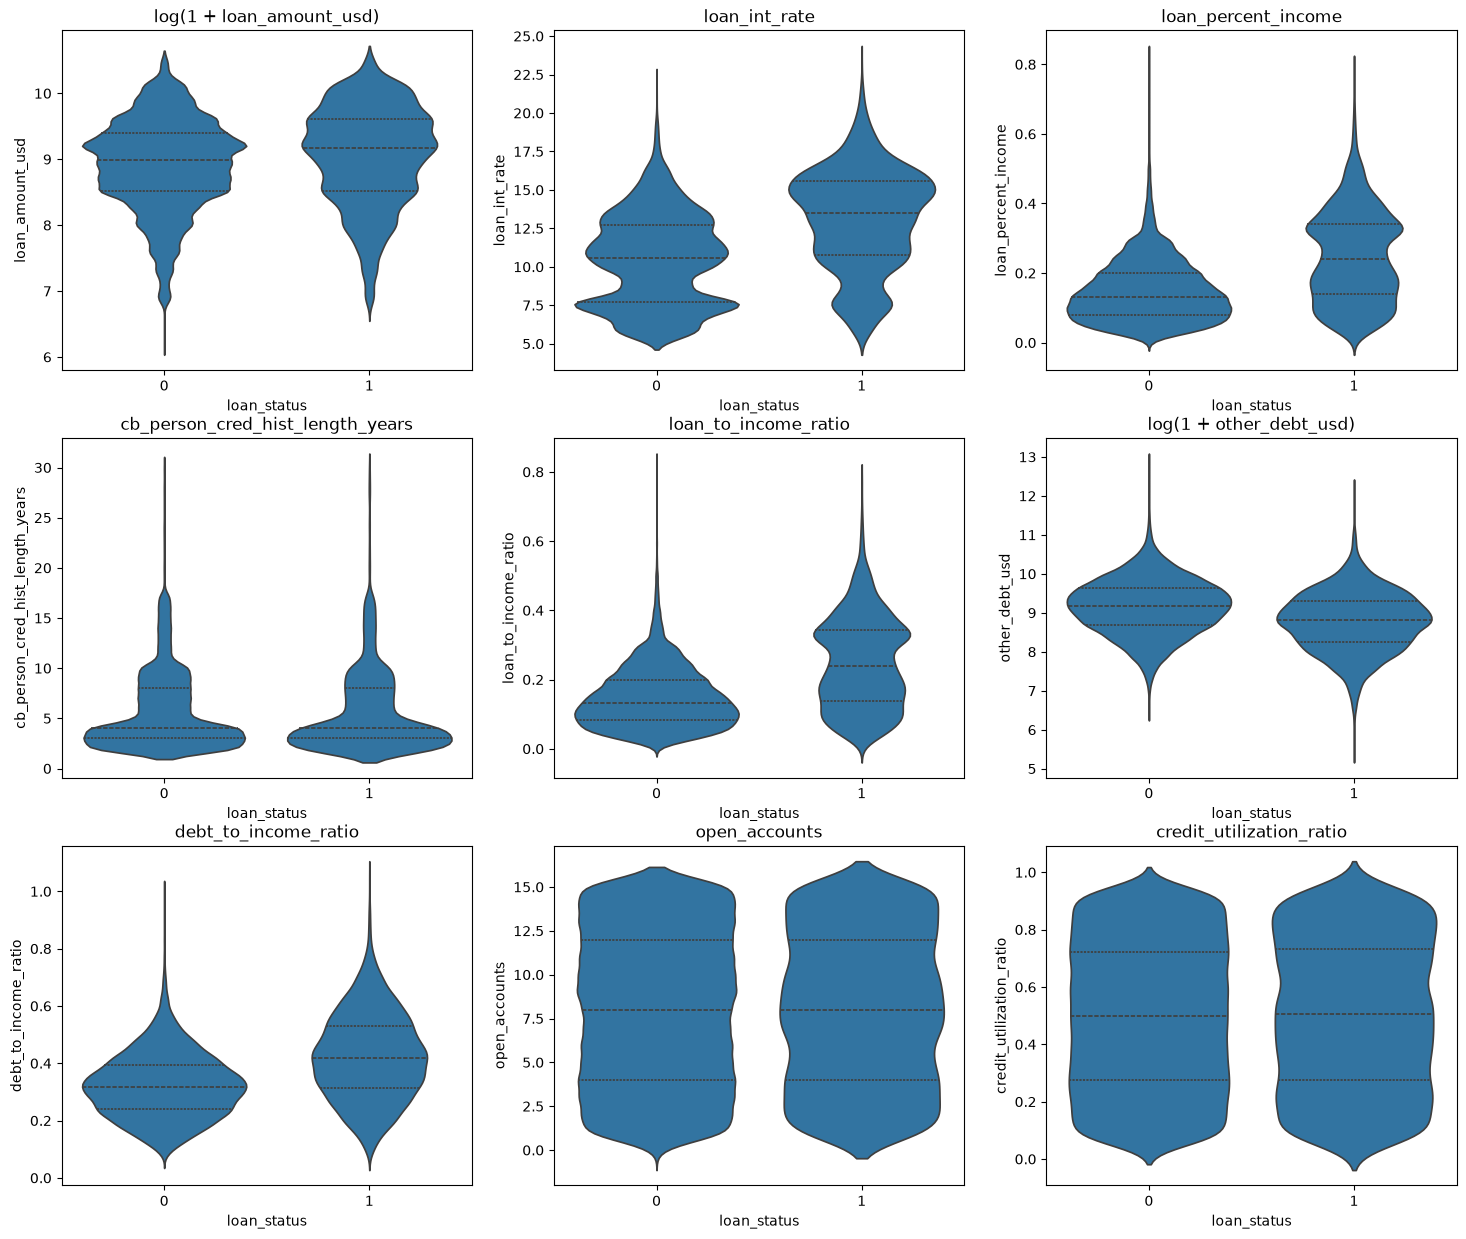

In [160]:
# plot again, but violin plots for better visualization of the distribution
target_col = "loan_status"
num_fin_features = [fin_ft for fin_ft in fin_features if fin_ft in list(set(num_features) - set(mixed))]
ncols = 3
nrows = (len(num_fin_features) + ncols - 1) // ncols
fig, axes = plt.subplots(nrows, ncols, figsize=(18, 5 * nrows))
axes = np.atleast_1d(axes).ravel()
for ft, ax in zip(num_fin_features, axes):
    if ft in ["loan_amount_usd", "other_debt_usd"]:
        # plot log of amounts
        sns.violinplot(x=df[target_col], y=np.log1p(df[ft]), inner="quartiles", ax=ax)
        ax.set_title(f"log(1 + {ft})")
    else:
        sns.violinplot(x=df[target_col], y=df[ft], inner="quartiles", ax=ax)
        ax.set_title(ft)
for ax in axes[len(num_fin_features):]:
    ax.set_visible(False)

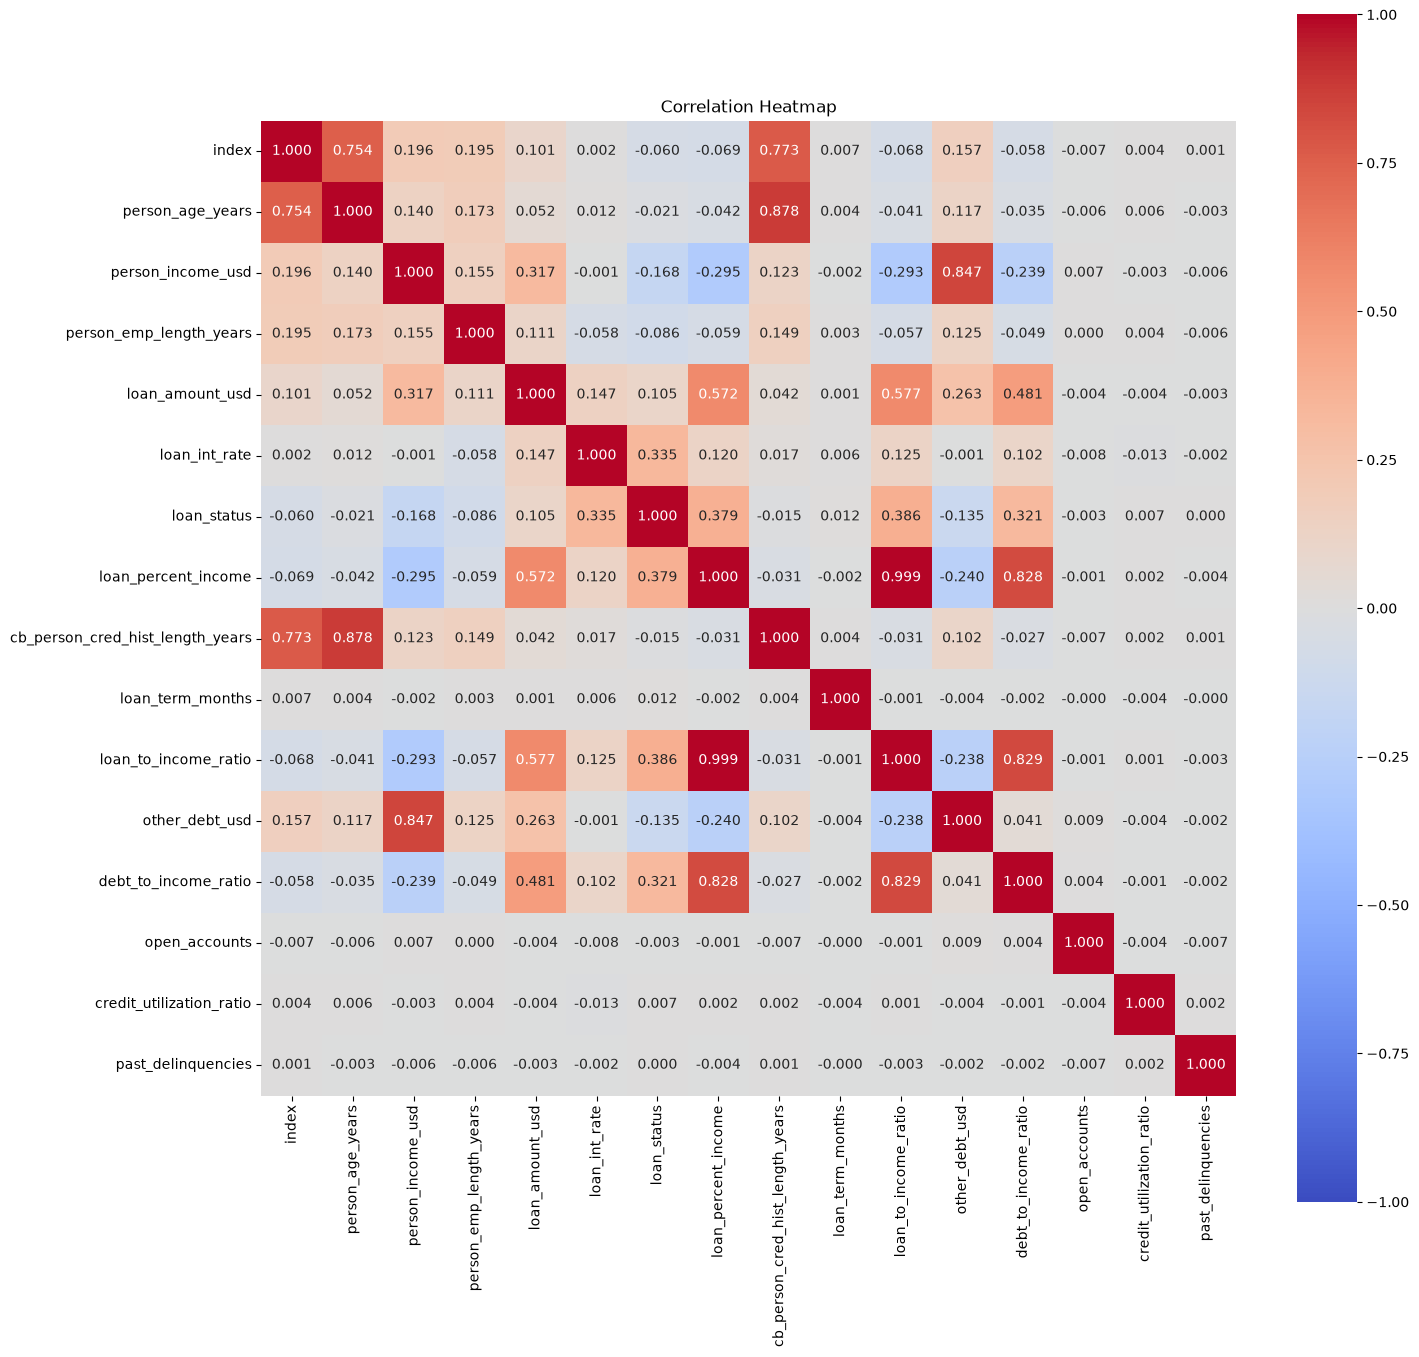

In [161]:
# Correlations among numeric features and the target; exclude ID and location coordinates
corr = (
    df.select_dtypes(include="number")
      .drop(columns=["client_ID", "city_latitude", "city_longitude"], errors="ignore")
      .corr()
)

fig, ax = plt.subplots(figsize=(15, 14))
sns.heatmap(
    corr,
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    annot=True,
    fmt=".3f",
    square=True,
    ax=ax,
)
ax.set_title("Correlation Heatmap")
plt.tight_layout()
plt.show()

<Axes: xlabel='loan_to_income_ratio', ylabel='loan_percent_income'>

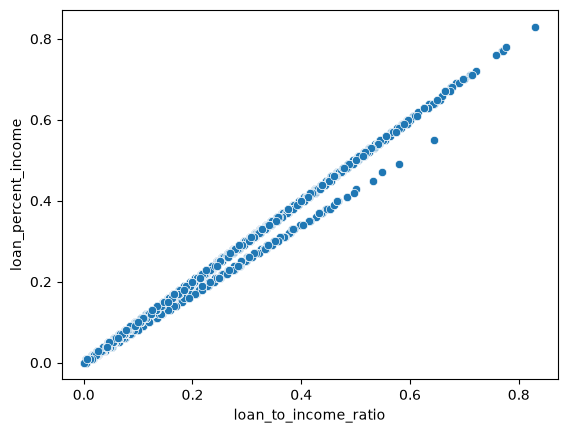

In [162]:
# check near-1.0 correlation between loan_to_income_ratio and loan_percent_income
sns.scatterplot(data=df, x="loan_to_income_ratio", y="loan_percent_income") 

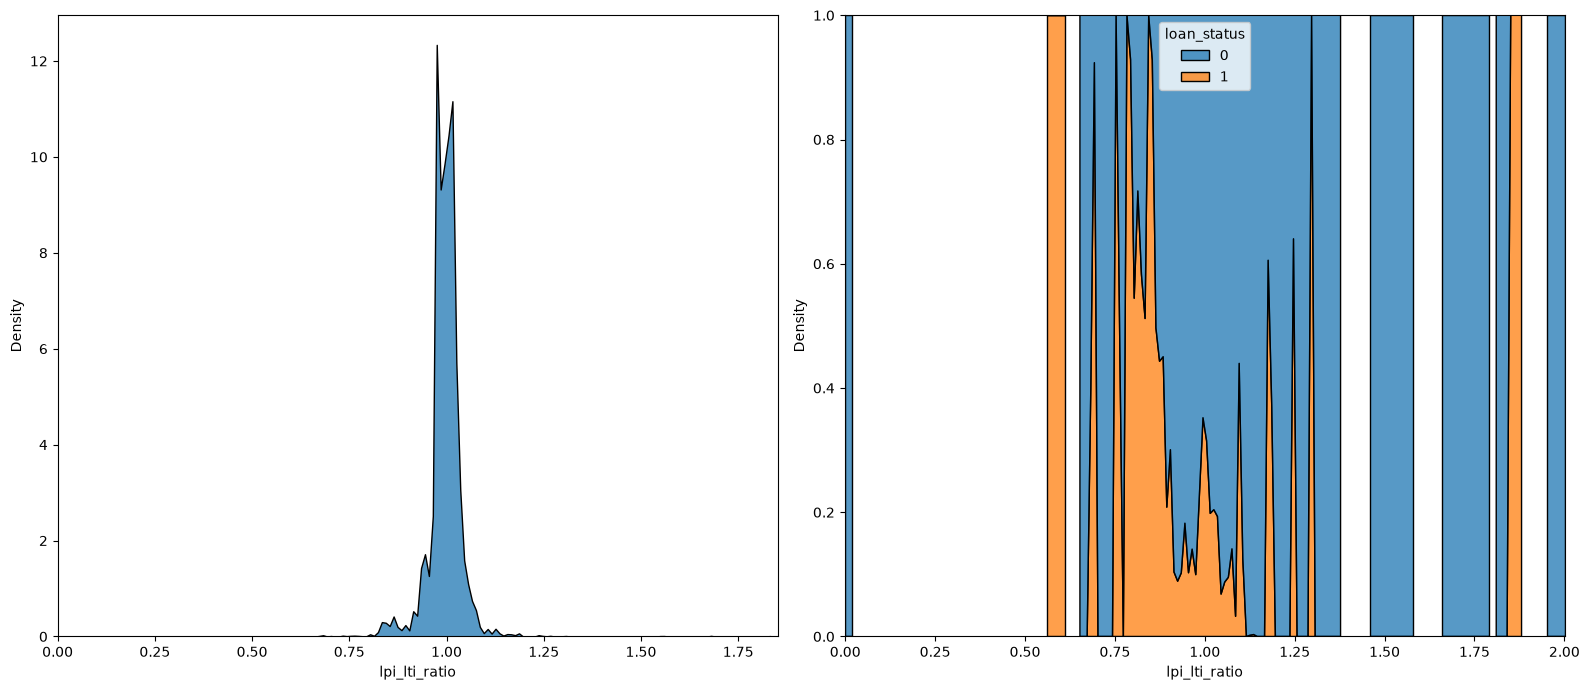

In [163]:
df["lpi_lti_ratio"] = df["loan_percent_income"] / df["loan_to_income_ratio"].replace(0, np.nan)
fig, axes = plt.subplots(1,2, figsize=(16,7))
sns.kdeplot(data=df, x="lpi_lti_ratio", hue="loan_status", bw_adjust=.1, multiple="fill", ax=axes[1])
sns.kdeplot(data=df, x="lpi_lti_ratio", bw_adjust=.15, multiple="stack", ax=axes[0])
axes[0].set_xlim(df["lpi_lti_ratio"].quantile(0.0001), df["lpi_lti_ratio"].quantile(0.9999))
plt.tight_layout()


<Axes: xlabel='None', ylabel='None'>

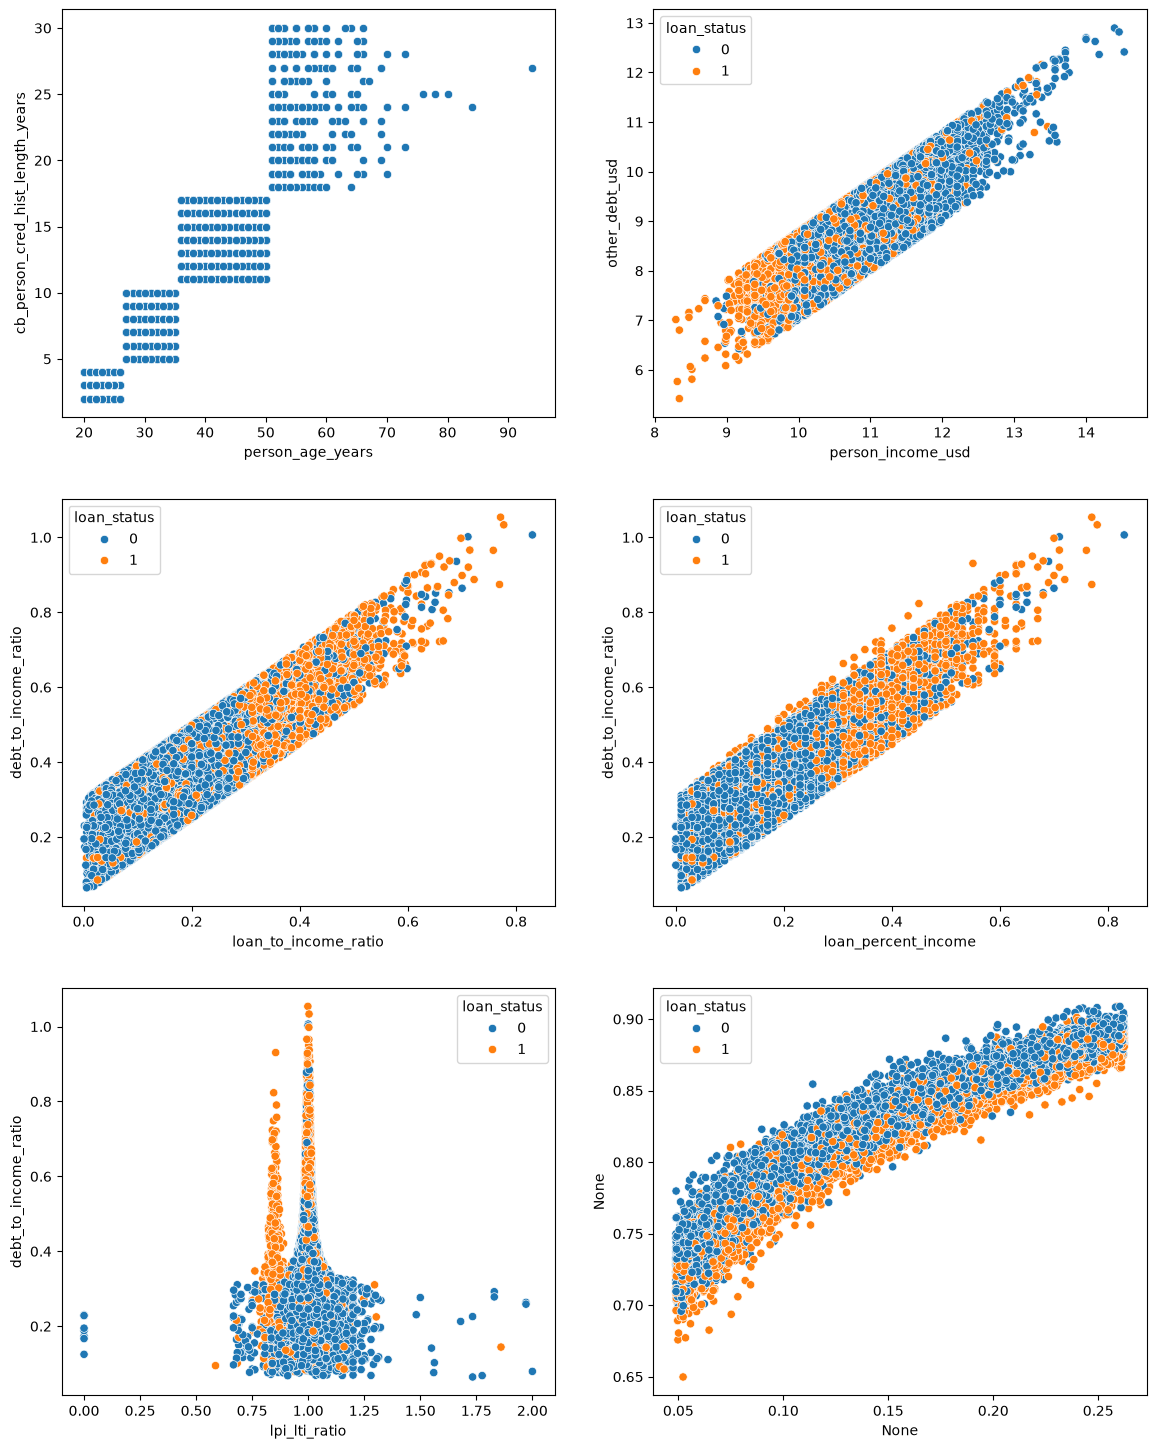

In [164]:
# plot other pairs of correlation > 0.8 and their derivatives
fig, ax = plt.subplots(3,2,figsize=(14,18))
sns.scatterplot(data=df, y="cb_person_cred_hist_length_years", x="person_age_years", ax=ax[0][0])
sns.scatterplot(y=np.log1p(df["other_debt_usd"]), x=np.log1p(df["person_income_usd"]), hue=df["loan_status"], ax=ax[0][1])
sns.scatterplot(data=df, y="debt_to_income_ratio", x="loan_to_income_ratio", hue="loan_status", ax=ax[1][0])
sns.scatterplot(data=df, y="debt_to_income_ratio", x="loan_percent_income", hue="loan_status", ax=ax[1][1])
sns.scatterplot(data=df, y="debt_to_income_ratio", x="lpi_lti_ratio", hue="loan_status", ax=ax[2][0])
sns.scatterplot(y=np.log1p(df["other_debt_usd"])/np.log1p(df["person_income_usd"]), x=np.log1p(df["other_debt_usd"]/df["person_income_usd"]), hue=df["loan_status"], ax=ax[2][1])

In [165]:
# debt = loan + other_debt, so strong correlation -> split it
df["other_debt_to_income_ratio"] = df["debt_to_income_ratio"] - df["loan_to_income_ratio"]

# now other_debt can be removed

In [166]:
new_cols = ["lpi_lti_ratio", "other_debt_to_income_ratio"]
redundant_cols = ["loan_percent_income", "debt_to_income_ratio", "other_debt"]

cols_to_keep = (kept_cat_dem_features + num_dem_features + 
                cat_fin_features + num_fin_features + new_cols + ["loan_status"])
cols_to_keep = [c for c in cols_to_keep if c not in redundant_cols]    # remove collinearity


# to df and save
df_processed = df[cols_to_keep].copy()

In [167]:
# log transform loan and debt amounts
cols_to_transform = ["person_income_usd", "loan_amount_usd"]
for c in cols_to_transform:
    df_processed[f"log_{c}"] = np.log1p(df_processed[c]) 

df_processed = df_processed.drop(columns=cols_to_transform)

df_processed

,person_home_ownership,person_emp_length_years,person_age_years,loan_intent,loan_grade,cb_person_default_on_file,loan_term_months,past_delinquencies,loan_int_rate,cb_person_cred_hist_length_years,loan_to_income_ratio,other_debt_usd,open_accounts,credit_utilization_ratio,lpi_lti_ratio,other_debt_to_income_ratio,loan_status,log_person_income_usd,log_loan_amount_usd
0,OWN,5.0,21,EDUCATION,B,N,36,3,11.14,2,0.104167,1607.802794,10,0.585436,0.960000,0.167479,0,9.169623,6.908755
1,MORTGAGE,1.0,25,MEDICAL,C,N,36,0,12.87,3,0.572917,2760.505633,14,0.750732,0.994909,0.287553,1,9.169623,8.612685
2,RENT,4.0,23,MEDICAL,C,N,12,0,15.23,2,0.534351,7155.286150,15,0.379333,0.991857,0.109241,1,11.089821,10.463132
3,RENT,8.0,24,MEDICAL,C,Y,36,0,14.27,4,0.643382,15626.153440,4,0.228103,0.854857,0.287245,1,10.904138,10.463132
4,OWN,2.0,21,VENTURE,A,N,36,0,7.14,2,0.252525,2211.741134,10,0.827034,0.990000,0.223408,1,9.200391,7.824446
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
32569,MORTGAGE,1.0,57,PERSONAL,C,N,36,1,13.16,30,0.109434,15721.464520,11,0.892039,1.005172,0.296631,0,10.878066,8.665786
32570,MORTGAGE,4.0,54,PERSONAL,A,N,60,0,7.49,19,0.146875,29674.399350,6,0.191486,1.021277,0.247287,0,11.695255,9.777130
32571,RENT,3.0,65,HOMEIMPROVEMENT,B,N,24,3,10.99,28,0.460526,21098.865050,11,0.678980,0.998857,0.277617,1,11.238502,10.463132
32572,MORTGAGE,5.0,56,PERSONAL,B,N,36,1,11.48,26,0.100000,26361.525750,3,0.223460,1.000000,0.175744,0,11.918397,9.615872


In [168]:
# save to files
df_processed.to_csv("../data/processed-data/processed_data.csv")